# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Mochamad Haikal
- **Email:** mochamadhaikal07@gmail.com
- **ID Dicoding:** DS284B6Y1002

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana perkembangan rata-rata jumlah penyewaan sepeda setiap bulan selama periode Januari 2011 hingga Desember 2012, dan bulan apa yang memiliki rata-rata penyewaan tertinggi?
- **Pertanyaan 2:** Seberapa besar perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca selama periode Januari 2011 hingga Desember 2012, dan kondisi cuaca apa yang menghasilkan jumlah penyewaan tertinggi?

## Import Semua Packages/Library yang Digunakan

In [44]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import zipfile
import io
import os

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)

sns.set_theme(style="whitegrid")

print("Semua library berhasil diimpor!")

Semua library berhasil diimpor!


In [45]:
from google.colab import files

uploaded = files.upload()

Saving Bike-sharing-dataset.zip to Bike-sharing-dataset.zip


## Data Wrangling

### Gathering Data

#### Load df ...

In [46]:
zip_file = zipfile.ZipFile('Bike-sharing-dataset.zip')

print("Daftar file dalam dataset:")
print(zip_file.namelist())

with zip_file.open('day.csv') as file:
  df = pd.read_csv(file)

print("\nDataset berhasil dimuat")
print("Jumlah baris dan kolom:", df.shape)

Daftar file dalam dataset:
['Readme.txt', 'day.csv', 'hour.csv']

Dataset berhasil dimuat
Jumlah baris dan kolom: (731, 16)


In [47]:
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [48]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [49]:
df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


**Insight:**
- Dataset Bike Sharing yang digunakan merupakan data penyewaan sepeda berdasarkan harian (`day.csv`).
- Dataset memiliki 731 baris dan 16 kolom.
- Data mencakup periode 1 Januari 2011 sampai 31 Desember 2012.
- Dataset memiliki informasi waktu, musim, kondisi cuaca, suhu, kelembaban, serta jumlah penyewaan sepeda.
- Kolom `cnt` menunjukkan total peneyewaan sepeda, sedangkan `casual` dan `registered` menunjukkan jumlah penyewaan dari masing-masing jenis pengguna.

### Assessing Data

#### Identifying ... problem

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [51]:
df.dtypes

,0
instant,int64
dteday,object
season,int64
yr,int64
mnth,int64
holiday,int64
weekday,int64
workingday,int64
weathersit,int64
temp,float64


In [52]:
df.isnull().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


In [53]:
print("Jumlah duplikat:", df.duplicated().sum())

Jumlah duplikat: 0


In [54]:
kolom_kategorikal = [
    'season', 'yr', 'mnth', 'holiday',
    'weekday', 'workingday', 'weathersit'
]

for kolom in kolom_kategorikal:
    print(f"\nNilai unik kolom {kolom}:")
    print(sorted(df[kolom].unique()))


Nilai unik kolom season:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

Nilai unik kolom yr:
[np.int64(0), np.int64(1)]

Nilai unik kolom mnth:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]

Nilai unik kolom holiday:
[np.int64(0), np.int64(1)]

Nilai unik kolom weekday:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]

Nilai unik kolom workingday:
[np.int64(0), np.int64(1)]

Nilai unik kolom weathersit:
[np.int64(1), np.int64(2), np.int64(3)]


In [55]:
df.describe().loc[['min', 'max']]

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
min,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.059130,0.079070,0.0000,0.022392,2.0,20.0,22.0
max,731.0,4.0,1.0,12.0,1.0,6.0,1.0,3.0,0.861667,0.840896,0.9725,0.507463,3410.0,6946.0,8714.0


**Steps to Take:**
- Memeriksa struktur dataset menggunakan fungsi `df.info()` untuk mengetahui jumlah data, nama kolom, dan tipe data setiap kolom.
- Memeriksa tipe data setiap kolom menggunakan `df.dtypes` untuk mengetahui apakah terdapat tipe data yang perlu diperbaiki.
- Memeriksa missing values menggunakan `df.isnull().sum()` untuk mengetahui apakah terdapat baris data yang tercatat lebih dari satu kali.
- Memeriksa nilai unik pada kolom kategorikal seperti `season`, `yr`, `mnth`, `holiday`, `weekday`, `workingday`, dan `weathersit`.
- Memeriksa nilai minimum dan maksimum setiap kolom numerik menggunakan `df.describe()` untuk mengetahui rentang nilai data.

**Insight:**
- Pemeriksaan missing values dilakukan untuk mengetahui apakah terdapat data kosong pada setiap kolom.
- Pemeriksaan duplikasi dilakukan untuk mengetahui apakah terdapat baris data yang tercatat lebih dari satu kali.
- Kolom `dteday` perlu diperiksa tipe datanya karena masih dapat terbaca sebagai object, padahal berisi informasi tanggal.
- Beberapa kolom seperti `season`, `mnth`, `weekday`, dan `weathersit` menggungakan angka sebagai kode kategori sehingga perlu diperhatikan agar lebih mudah dipahami saat analisis.
- Pemeeriksaan nilai unik dan rentang data dilakukan untuk memastikan nilai pada setiap kolom sesuai dengan ketentuan dataset.

### Cleaning Data

#### Fixing ... problem

In [56]:
df_clean = df.copy()

df_clean['dteday'] = pd.to_datetime(df_clean['dteday'])

print("Tipe data dteday setelah diperbaiki:")
print(df_clean['dteday'].dtypes)

Tipe data dteday setelah diperbaiki:
datetime64[ns]


In [57]:
jumlah_duplikat = df_clean.duplicated().sum()

print("Jumlah data duplikat:", jumlah_duplikat)

if jumlah_duplikat > 0:
   df_clean = df_clean.drop_duplicates()
   print("Data duplikat berhasil dihapus.")
else:
   print("Tidak ada data duplikat yang ditemukan.")

Jumlah data duplikat: 0
Tidak ada data duplikat yang ditemukan.


In [58]:
print("Missing values sebelum cleaning:")
print(df_clean.isnull().sum())

jumlah_missing = df_clean.isnull().sum().sum()

if jumlah_missing > 0:
    df_clean = df_clean.dropna()
    print("\nMissing values berhasil dihapus.")
else:
    print("\nTidak ada missing values yang ditemukan.")

print("\nMissing values setelah cleaning:")
print(df_clean.isnull().sum())

Missing values sebelum cleaning:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Tidak ada missing values yang ditemukan.

Missing values setelah cleaning:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [59]:
season_mapping = {
    1: 'spring',
    2: 'summer',
    3: 'fall',
    4: 'winter'
}

df_clean['season_label'] = df_clean['season'].map(season_mapping)

weather_mapping = {
    1: 'clear',
    2: 'mist + Cloudy',
    3: 'light rain/Snow',
    4: 'heavy rain/Snow'
}

df_clean['weather_label'] = df_clean['weathersit'].map(weather_mapping)

year_mapping = {
    0: 2011,
    1: 2012
}

df_clean['year'] = df_clean['yr'].map(year_mapping)

df_clean['month_name'] = df_clean['dteday'].dt.month_name()

df_clean['month'] = df_clean['dteday'].dt.month

print("Kolom tambahan berhasil dibuat")

Kolom tambahan berhasil dibuat


In [60]:
df_clean.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,season_label,weather_label,year,month_name,month
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985,spring,mist + Cloudy,2011,January,1
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801,spring,mist + Cloudy,2011,January,1
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349,spring,clear,2011,January,1
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562,spring,clear,2011,January,1
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600,spring,clear,2011,January,1


In [61]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   instant        731 non-null    int64         
 1   dteday         731 non-null    datetime64[ns]
 2   season         731 non-null    int64         
 3   yr             731 non-null    int64         
 4   mnth           731 non-null    int64         
 5   holiday        731 non-null    int64         
 6   weekday        731 non-null    int64         
 7   workingday     731 non-null    int64         
 8   weathersit     731 non-null    int64         
 9   temp           731 non-null    float64       
 10  atemp          731 non-null    float64       
 11  hum            731 non-null    float64       
 12  windspeed      731 non-null    float64       
 13  casual         731 non-null    int64         
 14  registered     731 non-null    int64         
 15  cnt            731 non-

In [62]:
print("Ukuran dataset sebelum cleaning:", df.shape)
print("Ukuran dataset setelah cleaning:", df_clean.shape)

Ukuran dataset sebelum cleaning: (731, 16)
Ukuran dataset setelah cleaning: (731, 21)


**Insight:**
- Tipe data kolom `dteday` telah disesuaikan menjadi datetime agar dapat digunakan untuk analisis berdasarkan tanggal.
- Data duplikat telah diperiksa dan dihapus apabila ditemukan.
- Missing values telah diperiksa dan ditangani apabila ditemukan.
- Beberapa kolom kategori telah ditambahkan label deskriptif agar lebih mudah dipahami.
Kolom tahun dan bulan ditambahkan untuk mempermudah analisis perkembangan penyewaan sepeda.
- Dataset yang telah dibersihkan disimpan dalam variabel `df_clean` dan akan digunakan pada tahap analisis selanjutnya.

## Exploratory Data Analysis (EDA)

### Explore ...

In [63]:
monthly_rentals = df_clean.groupby(
    ['year', 'month']
).agg(
    average_rentals=('cnt', 'mean')
).reset_index()

monthly_rentals['date'] = pd.to_datetime(
    monthly_rentals['year'].astype(str) + '-' +
    monthly_rentals['month'].astype(str) + '-01'
)

monthly_rentals = monthly_rentals.sort_values('date')

monthly_rentals

,year,month,average_rentals,date
0,2011,1,1231.903226,2011-01-01
1,2011,2,1721.964286,2011-02-01
2,2011,3,2065.967742,2011-03-01
3,2011,4,3162.333333,2011-04-01
4,2011,5,4381.322581,2011-05-01
...,...,...,...,...
19,2012,8,6919.451613,2012-08-01
20,2012,9,7285.766667,2012-09-01
21,2012,10,6414.225806,2012-10-01
22,2012,11,5088.800000,2012-11-01


In [64]:
highest_month = monthly_rentals.loc[
    monthly_rentals['average_rentals'].idxmax()
]

lowest_month = monthly_rentals.loc[
    monthly_rentals['average_rentals'].idxmin()
]

print("Bulan dengan rata-rata penyewaan tertinggi:")
print(highest_month)

print("\nBulan dengan rata-rata penyewaan terendah:")
print(lowest_month)

Bulan dengan rata-rata penyewaan tertinggi:
year                              2012
month                                9
average_rentals            7285.766667
date               2012-09-01 00:00:00
Name: 20, dtype: object

Bulan dengan rata-rata penyewaan terendah:
year                              2011
month                                1
average_rentals            1231.903226
date               2011-01-01 00:00:00
Name: 0, dtype: object


In [65]:
weather_rentals = df_clean.groupby(
    'weather_label'
).agg(
    average_rentals=('cnt', 'mean'),
    total_rentals=('cnt', 'sum'),
    number_of_days=('cnt', 'count')
).reset_index()

weather_rentals = weather_rentals.sort_values(
    by='average_rentals',
    ascending=False
)

weather_rentals

,weather_label,average_rentals,total_rentals,number_of_days
0,clear,4876.786177,2257952,463
2,mist + Cloudy,4035.862348,996858,247
1,light rain/Snow,1803.285714,37869,21


In [66]:
highest_weather = weather_rentals.iloc[0]

lowest_weather = weather_rentals.iloc[-1]

print("Kondisi cuaca dengan rata-rata penyewaan tertinggi:")
print(highest_weather)

print("\nKondisi cuaca dengan rata-rata penyewaan terendah:")
print(lowest_weather)

Kondisi cuaca dengan rata-rata penyewaan tertinggi:
weather_label            clear
average_rentals    4876.786177
total_rentals          2257952
number_of_days             463
Name: 0, dtype: object

Kondisi cuaca dengan rata-rata penyewaan terendah:
weather_label      light rain/Snow
average_rentals        1803.285714
total_rentals                37869
number_of_days                  21
Name: 1, dtype: object


In [67]:
weather_diff = (
    highest_weather['average_rentals'] -
    lowest_weather['average_rentals']
)

print(
    "Selisih rata-rata penyewaan antara kondisi cuaca tertinggi dan terendah:",
    round(weather_diff, 2),
    "sepeda"
)


Selisih rata-rata penyewaan antara kondisi cuaca tertinggi dan terendah: 3073.5 sepeda


**Insight:**
- Berdasarkan pengelompokan data berdasarkan tahun dan bulan, terlihat perkembangan rata-rata penyewaan sepeda selama periode 2011-2012.
- Bulan dengan rata-rata penyewaan tertinggi adalah September 2012 dengan rata-rata 7285.76 sepeda per hari.
- Bulan dengan rata-rata penyewaan terendah adalah Januari 2011 dengan rata-rata 1231.90 sepeda per hari.
- Berdasarkan kondisi cuaca, rata-rata penyewaan sepeda tertinggi terjadi pada kondisi clear dengan rata-rata 4876.78 sepeda per hari.
- Rata-rata penyewaan terendah terjadi pada kondisi light rain/snow dengan rata-rata 1803.28 sepeda per hari.
- Terdapat selisih rata-rata penyewaan sebesar 3073.5 sepeda antara kondisi cuaca dengan rata-rata penyewaan tertinggi dan terendah.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

Text(0, 0.5, 'Rata-rata Penyewaan Sepeda per Hari')

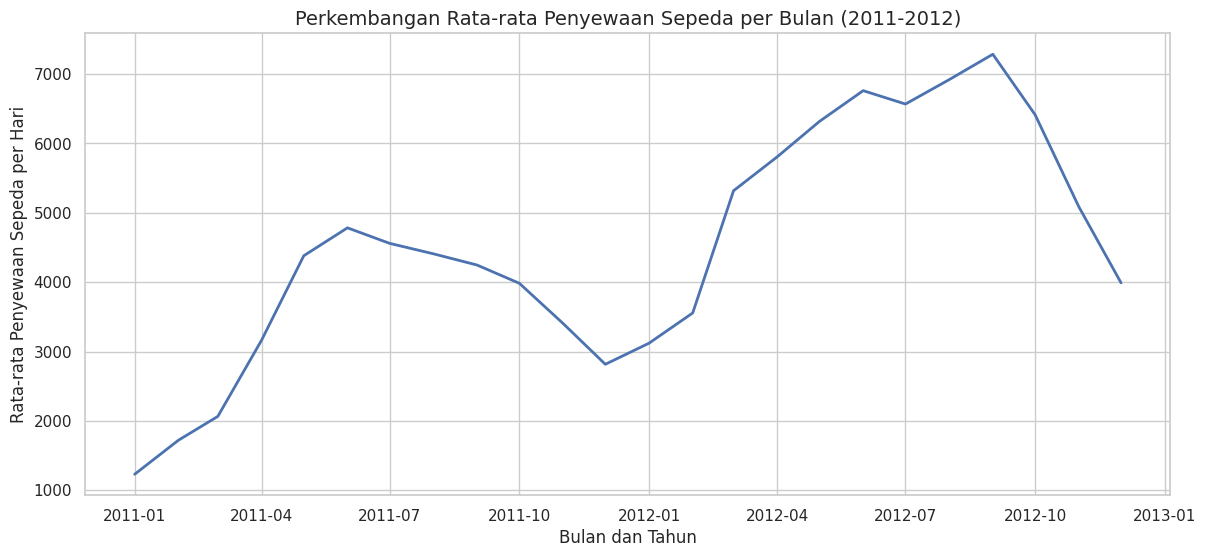

In [68]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_rentals,
    x='date',
    y='average_rentals',
    markers='0',
    linewidth=2
)

plt.title(
    'Perkembangan Rata-rata Penyewaan Sepeda per Bulan (2011-2012)',
    fontsize=14
)
plt.xlabel('Bulan dan Tahun')
plt.ylabel('Rata-rata Penyewaan Sepeda per Hari')

### Pertanyaan 2:

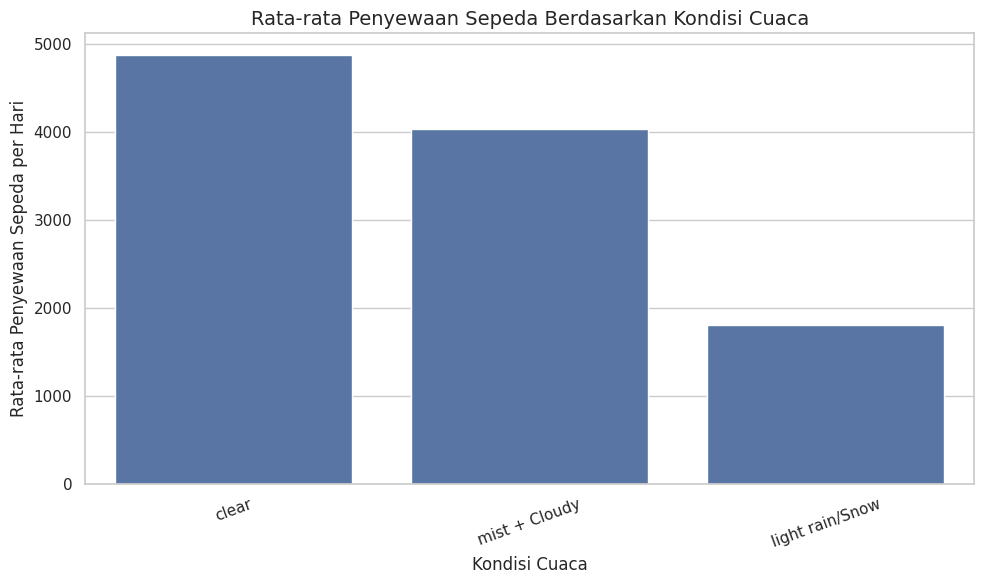

In [69]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=weather_rentals,
    x='weather_label',
    y='average_rentals',
)

plt.title(
    'Rata-rata Penyewaan Sepeda Berdasarkan Kondisi Cuaca',
    fontsize=14
)
plt.xlabel('Kondisi Cuaca')
plt.ylabel('Rata-rata Penyewaan Sepeda per Hari')

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Insight:**
- Pada pertanyaan 1, grafik menunjukkan adanya perubahan rata-rata penyewaan sepeda selama Januari 2011 hingga Desember 2012. Bulan dengan rata-rata penyewaan tertinggi adalah September 2012 dengan rata-rata 7285.76 sepeda per hari. Pola kenaikan dan penurunan penyewaan dapat digunakan sebagai bahan pertimbangan untuk mengatur ketersediaan sepeda pada periode tertentu.
- Pada pertanyaan 2, grafik menunjukkan bahwa rata-rata penyewaan sepeda berbeda berdasarkan kondisi cuaca. Kondisi cuaca dengan rata-rata penyewaan tertinggi adalah clear dengan rata-rata 4876.78 sepeda per hari. Selisih rata-rata penyewaan antara kondisi cuaca tertinggi dan terendah adalah 3073.5 sepeda per hari. Kondisi cuaca menjadi salah satu faktor yang perlu dipertimbangkan dalam memperkirakan permintaan penyewaan sepeda.

## Analisis Lanjutan (Opsional)

**Insight:** (Opsional)
- xxx
- xxx

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Berdasarkan hasil analisis, rata-rata penyewaan sepeda mengalami perubahan dari bulan ke bulan. Bulan dengan rata-rata penyewaan tertinggi adalah September 2012 dengan rata-rata 7285.76 sepeda per hari. Hasil ini menunjukkan bahwa terdapat periode tertentu ketika permintaan penyewaan sepeda meningkat sehingga pengelola perlu memperhatikan ketersediaan sepeda pada periode tersebut.
- **Conclusion pertanyaan 2:** Hasil analisis menunjukkan bahwa kondisi cuaca memiliki hubungan dengan jumlah penyewaan sepeda. Rata-rata penyewaan tertinggi terjadi pada kondisi clear dengan rata-rata 4876.78 sepeda per hari, sedangkan rata-rata terendah terjadi pada kondisi light rain/snow. Hal ini menunjukkan bahwa kondisi cuaca dapat menjadi salah satu faktor yang perlu dipertimbangkan dalam memperkirakan permintaan penyewaan sepeda.

**Rekomendasi Action Item:**
- Mengoptimalkan ketersediaan sepeda berdasarkan periode permintaan. Pengelola sebaiknya menyiapkan lebih banyak sepeda pada bulan-bulan dengan rata-rata penyewaan tinggi agar kebutuhan pengguna dapat terpenuhi.
- Mempertimbangkan kondisi cuaca dalam operasional. Pengelola dapat menyesuaikan jumlah sepeda yang disiapkan berdasarkan perkiraan cuaca. Pada kondisi cuaca yang kurang mendukung, pengelola dapat mengatur kembali distribusi sepeda dan kegiatan operasional.
- Melakukan pemantauan permintaan secara berkala. Data penyewaan perlu dianalisis secara rutin agar pengelola dapat mengetahui perubahan pola permintaan dan membuat keputusan operasional yang lebih tepat.